In [1]:
# This cell is removed with the tag: "remove-input"
# As such, it will not be shown in documentation

import warnings
warnings.filterwarnings('ignore')


(Tutorial_Move_away)=
# Move away

*Translating a molecular selection away from a reference center by a fixed distance.*

The function {func}`molsysmt.structure.move_away` translates a target selection of atoms or an entire molecular system away from a reference center by a specified Euclidean distance along an automatic or user-defined 3D direction vector. Automatic mode adds to the existing separation; explicit direction sets the offset of the source center from the initial reference center. Both modes accept one structure and one center in each system.

:::{versionadded} 1.0.0
:::

:::{admonition} API documentation
:class: dropdown

Follow this link for a detailed description of the input arguments, raised errors, and returned objects of this function: {func}`molsysmt.structure.move_away`.
:::


## Basic usage

Let's show how to translate one alanine dipeptide molecule away from another by a specified distance:


In [2]:
import molsysmt as msm
import numpy as np
import pyunitwizard as puw


%matplotlib inline

In [3]:
molsys_A = msm.convert(msm.systems['alanine dipeptide']['alanine_dipeptide.h5msm'])
molsys_A = msm.structure.center(molsys_A)

molsys_B = msm.convert(msm.systems['alanine dipeptide']['alanine_dipeptide.h5msm'])
molsys_B = msm.structure.center(molsys_B)


:::{note}
:class: dropdown

**Demo Systems Catalog**

This tutorial uses demonstration datasets provided by MolSysMT. To explore the full catalog of bundled systems, forms, and file paths, visit the {ref}`Demo Systems <user-foundations-entrance-demo-systems>` guide.
:::


We translate `molsys_B` away from `molsys_A` by `2.0 nm` along the X-axis using {func}`molsysmt.structure.move_away`:


In [4]:
molsys_B_moved = msm.structure.move_away(molsys_B, reference_molecular_system=molsys_A, distance='2.0 nm', direction=[1.0, 0.0, 0.0])


In [5]:
center_A = msm.structure.get_center(molsys_A)
center_B = msm.structure.get_center(molsys_B_moved)
print('Center of molsys A:', center_A)
print('Center of molsys B after displacement:', center_B)


Center of molsys A: [[[5.0464682937507114e-17 -1.5139404881252134e-17 -2.523234146875356e-18]]] nanometer
Center of molsys B after displacement: [[[2.0000000000000004 -1.5139404881252134e-17 -2.523234146875356e-18]]] nanometer


## Directional displacement along arbitrary 3D vectors

We can displace the mobile system along any arbitrary spatial direction vector (e.g. diagonal unit vector $[1, 1, 0]$):


In [6]:
molsys_B_diag = msm.structure.move_away(molsys_B, reference_molecular_system=molsys_A, distance='3.0 nm', direction=[1.0, 1.0, 0.0])
center_diag = msm.structure.get_center(molsys_B_diag)
print('Center after diagonal translation:', center_diag)


Center after diagonal translation: [[[2.121320343559642 2.121320343559642 -2.523234146875356e-18]]] nanometer


## Quantitative verification of spatial separation

We verify that the Euclidean distance between the centroids matches the specified target distance:


In [7]:
disp_vector = puw.get_value(center_diag - center_A, to_unit="nm")
euclidean_distance = np.linalg.norm(disp_vector)
print(f'Measured Euclidean separation: {euclidean_distance:.4f} nm')

assert np.isclose(euclidean_distance, 3.0)

Measured Euclidean separation: 3.0000 nm


## Adding to an existing separation

An automatic direction adds distance to the current separation. Starting 1 nm
from the reference, a 2 nm increment produces a final separation of 3 nm.
Explicit direction uses the same initial system but sets the final offset to
2 nm. The reference center is measured before either edit.

Initial, automatic increment, explicit offset (nm): [np.float64(0.9999999999999999), np.float64(3.0000000000000013), np.float64(2.0000000000000004)]


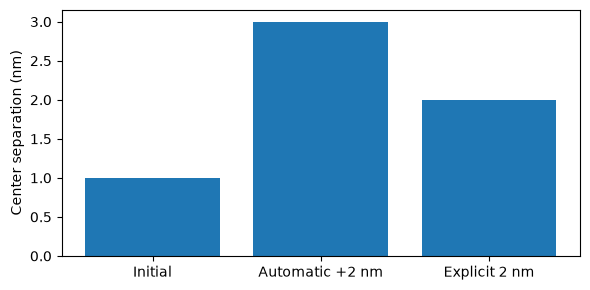

In [8]:
molsys_B_initial = msm.structure.translate(molsys_B, translation='[1, 0, 0] nm')
molsys_B_auto = msm.structure.move_away(
    molsys_B_initial, reference_molecular_system=molsys_A, distance='2 nm')
molsys_B_offset = msm.structure.move_away(
    molsys_B_initial, reference_molecular_system=molsys_A,
    direction=[1, 0, 0], distance='2 nm')
separations = [np.linalg.norm(puw.get_value(
    msm.structure.get_center(item) - center_A, to_unit='nm'))
    for item in [molsys_B_initial, molsys_B_auto, molsys_B_offset]]
np.testing.assert_allclose(separations, [1, 3, 2], atol=1e-12)
print('Initial, automatic increment, explicit offset (nm):', separations)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(['Initial', 'Automatic +2 nm', 'Explicit 2 nm'], separations)
ax.set_ylabel('Center separation (nm)')
fig.tight_layout()
plt.show()

## Choosing moving atoms and weighted centers

You can move a selected population while placing a contained source-center
population. Source and reference weights are independent; `masses` requests
atomic masses. Numeric weights follow the selected atom order, including repeated
center atoms. All moved atoms receive one common translation.

In [9]:
before_B = puw.get_value(msm.get(molsys_B, coordinates=True), to_unit='nm').copy()
reference = msm.structure.get_center(molsys_A, selection=[1, 3], weights='masses')
molsys_B_selected = msm.structure.move_away(
    molsys_B, selection=[0, 2, 4], center_of_selection=[0, 2], weights='masses',
    reference_molecular_system=molsys_A, reference_center_of_selection=[1, 3],
    reference_weights='masses', direction=[0, 0, 2], distance='5 angstrom')
source_after = msm.structure.get_center(
    molsys_B_selected, selection=[0, 2], weights='masses')
np.testing.assert_allclose(puw.get_value(source_after - reference, to_unit='nm'),
                           [[[0, 0, .5]]], atol=1e-12)
unchanged_atoms = sorted(set(range(before_B.shape[1])) - {0, 2, 4})
after_B = puw.get_value(msm.get(molsys_B_selected, coordinates=True), to_unit='nm')
np.testing.assert_array_equal(after_B[:, unchanged_atoms], before_B[:, unchanged_atoms])
np.testing.assert_array_equal(
    puw.get_value(msm.get(molsys_B, coordinates=True), to_unit='nm'), before_B)
print('Weighted source offset:', source_after - reference)

Weighted source offset: [[[0.0 5.551115123125783e-17 0.5]]] nanometer


## Rejecting undefined directions before editing

Coincident centers have no automatic direction. A zero or nonfinite explicit
vector is also undefined; requesting zero distance does not bypass this rule.
Use a finite nonzero explicit vector when source and reference centers coincide.

Only one structure and one reference structure are supported. Nonconsecutive
lists and repeated indices are still multiple requests, so they reject before
any edit. Empty populations, invalid weights and nonfinite distances also reject.
Coordinates, boxes and stored interaction coverage are preserved on rejection.
Successful native edits invalidate coverage only for the edited structure.
For independent output, the input and its analyses remain unchanged.

In [10]:
molsys_B_ensemble = msm.convert(
    msm.systems['pentalanine']['traj_pentalanine.h5msm'], structure_indices=[0, 8, 3])
before = puw.get_value(msm.get(molsys_B_ensemble, coordinates=True), to_unit='nm').copy()
for options in [{}, {'direction': [0, 0, 0]},
                {'direction': [1, 0, 0], 'structure_indices': [2, 0]}]:
    try:
        msm.structure.move_away(molsys_B_ensemble, in_place=True, **options)
    except (msm.ArgumentError, msm.NotImplementedMethodError) as error:
        print('Rejected without editing:', type(error).__name__)
    else:
        raise AssertionError('The unsupported call unexpectedly succeeded')
    np.testing.assert_array_equal(
        puw.get_value(msm.get(molsys_B_ensemble, coordinates=True), to_unit='nm'), before)

# A singleton list selects structure 2; all others stay fixed.
molsys_B_one = msm.structure.move_away(
    molsys_B_ensemble, structure_indices=[2], direction=[1, 0, 0])
np.testing.assert_array_equal(
    puw.get_value(msm.get(molsys_B_one, coordinates=True), to_unit='nm')[:2], before[:2])

Rejected without editing: ArgumentError
Rejected without editing: ArgumentError
Rejected without editing: NotImplementedMethodError


:::{seealso}
:class: dropdown

**Related Tools & References**

- {ref}`Convert <Tutorial_Convert>`: Convert molecular systems between different forms with {func}`molsysmt.basic.convert`.
- {ref}`Center <Tutorial_Center>`: Center coordinates on the geometric origin with {func}`molsysmt.structure.center`.
- {ref}`Get center <Tutorial_Get_center>`: Compute the geometric center or center of mass with {func}`molsysmt.structure.get_center`.
- {ref}`Get distances <Tutorial_Get_distances>`: Compute pairwise Euclidean distances with {func}`molsysmt.structure.get_distances`.
- {ref}`Get principal axes <Tutorial_Get_principal_axes>`: Compute the principal axes and moments of inertia with {func}`molsysmt.structure.get_principal_axes`.
:::
